In [1]:
import geopandas as gpd
import pandas as pd
from plotly import express as px
import statsmodels.api as sm

from data.constants import WEB_CRS

In [2]:
tract_file_in = "../data/interim/tracts.geoparquet"
comm_file_in = "../data/interim/communities.geojson"

point_panel_in = "../data/final/point_panel.parquet"
line_panel_in = "../data/final/line_panel.parquet"
tract_panel_in = "../data/final/tract_panel.parquet"
comm_panel_in = "../data/final/comm_panel.parquet"

# Pipeline in

In [3]:
tracts = gpd.read_parquet(tract_file_in)
comms = gpd.read_file(comm_file_in)

point_panel = pd.read_parquet(point_panel_in)
line_panel = pd.read_parquet(line_panel_in)
tract_panel = pd.read_parquet(tract_panel_in)
comm_panel = pd.read_parquet(comm_panel_in)

In [4]:
point_panel_wkd = point_panel[~point_panel['is_weekend'].astype(bool)]
line_panel_wkd = line_panel[~line_panel['is_weekend'].astype(bool)]
tract_panel_wkd = tract_panel[~tract_panel['is_weekend'].astype(bool)]
comm_panel_wkd = comm_panel[~comm_panel['is_weekend'].astype(bool)]

# Validate

In [5]:
def count_ids(df):
    return df.groupby(['id','transit']).size().count()

In [6]:
def plot_avg_completion(df):
    n_ids = count_ids(df)
    plot_data = df.groupby('date',sort=True).apply(count_ids, include_groups=False) / n_ids
    return px.line(x=plot_data.index, y=plot_data, title="panel completion")

In [7]:
def plot_transit_completion(df):
    n_ids = df.groupby('transit')[['transit','id']].apply(count_ids)
    plot_data = (df
             .groupby(['date','transit'],sort=True)
             [['transit','id']]
             .apply(count_ids)
             .rename('count')
             .reset_index()
             .assign(pct = lambda x: x['count'] / x['transit'].map(n_ids)))
    return px.line(plot_data, x='date', y='pct', color='transit',title="panel completion")

In [8]:
def completion_matrix(df,rows,cols):
    df = df.assign(exists=1).groupby([rows,cols])['exists'].any().astype(float)
    return df.reset_index().pivot(index=rows, columns=cols, values='exists').fillna(0)

def completion_long(df, rows, cols):
    mat = completion_matrix(df, rows, cols)
    return mat.reset_index().melt(id_vars=rows, var_name=cols, value_name='exists')

## Completion

In [9]:
plot_transit_completion(point_panel)

In [10]:
plot_transit_completion(line_panel)

In [11]:
plot_transit_completion(tract_panel)

# Completion: weekdays

In [12]:
plot_transit_completion(point_panel_wkd)

In [13]:
plot_transit_completion(line_panel_wkd)

In [14]:
plot_transit_completion(tract_panel_wkd)

In [15]:
plot_transit_completion(comm_panel_wkd)

# Predict drop-out

In [16]:
def minmax_scale(x):
    return (x - x.min()) / (x.max() - x.min())

def model_completion_data(df):
    model_data = completion_long(df, 'date','id')
    model_data['missing'] = 1 - model_data['exists']
    model_data['datenum'] = pd.to_datetime(model_data['date'],'coerce').apply(lambda x: x.timestamp())
    model_data['datenum'] = model_data['datenum'].pipe(minmax_scale)
    spacelike = df[['id','transit','lat','long']].drop_duplicates()
    spacelike['spacerides'] = spacelike['id'].map(df.groupby('id')['rides'].mean())
    timelike = df[['date','is_weekend']].drop_duplicates()
    timelike['timerides'] = timelike['date'].map(df.groupby('date')['rides'].mean())
    spacetimelike = df[['date','id','rides']].drop_duplicates()
    model_data = model_data.merge(spacelike, how='left')
    model_data = model_data.merge(timelike, how='left')
    model_data = model_data.merge(spacetimelike, how='left')
    model_data['rides'] = model_data['rides'].fillna(0)+1
    return model_data

def model_completion(df, formula=None):
    model_data = model_completion_data(df)
    default_formula = "missing ~ transit + is_weekend + lat + long + I(lat*long) + I(lat**2) + I(long**2)"
    formula = default_formula if formula is None else formula
    return sm.Logit.from_formula(formula, model_data).fit()

In [17]:
point_missing = model_completion_data(point_panel)
fig = px.scatter_matrix(point_missing, dimensions=['missing','datenum','lat','long'])
fig.update_traces(diagonal_visible=False)
# The point panel is okay.

In [18]:
line_missing = model_completion_data(line_panel)
fig = px.scatter_matrix(line_missing, dimensions=['missing','datenum','lat','long'])
fig.update_traces(diagonal_visible=False)
# The line panel is sort of ok.

In [19]:
tract_missing = model_completion_data(tract_panel)
fig = px.scatter_matrix(tract_missing, dimensions=['missing','datenum','lat','long'])
fig.update_traces(diagonal_visible=False)
# SAme pattern as point panel

In [20]:
comm_missing = model_completion_data(comm_panel)
fig = px.scatter_matrix(comm_missing, dimensions=['missing','datenum','lat','long'])
fig.update_traces(diagonal_visible=False)
# SAme pattern as point panel

In [21]:
# The all agg types have a decent chunk of ids that are missing some dates.
(point_missing.groupby('id')['missing'].any().mean(),
line_missing.groupby('id')['missing'].any().mean(),
tract_missing.groupby('id')['missing'].any().mean(),
comm_missing.groupby('id')['missing'].any().mean())

(np.float64(0.6536873156342183),
 np.float64(0.3082706766917293),
 np.float64(0.3968253968253968),
 np.float64(0.09090909090909091))

In [22]:
# Every date in the point and tract panel is missing at least some ids.
# Only a quarter of dates in the line panel are missing some ids.
(point_missing.groupby('date')['missing'].any().mean(),
line_missing.groupby('date')['missing'].any().mean(),
tract_missing.groupby('date')['missing'].any().mean(),
comm_missing.groupby('date')['missing'].any().mean())

(np.float64(1.0),
 np.float64(0.28888888888888886),
 np.float64(1.0),
 np.float64(0.05555555555555555))

In [23]:
# The line panel becomes a full panel when we subset to weekdays.
(point_missing[point_missing['is_weekend']==0].groupby('date')['missing'].any().mean(),
line_missing[line_missing['is_weekend']==0].groupby('date')['missing'].any().mean(),
tract_missing[tract_missing['is_weekend']==0].groupby('date')['missing'].any().mean(),
comm_missing[comm_missing['is_weekend']==0].groupby('date')['missing'].any().mean())

(np.float64(1.0),
 np.float64(0.015384615384615385),
 np.float64(1.0),
 np.float64(0.03076923076923077))

# Spatial

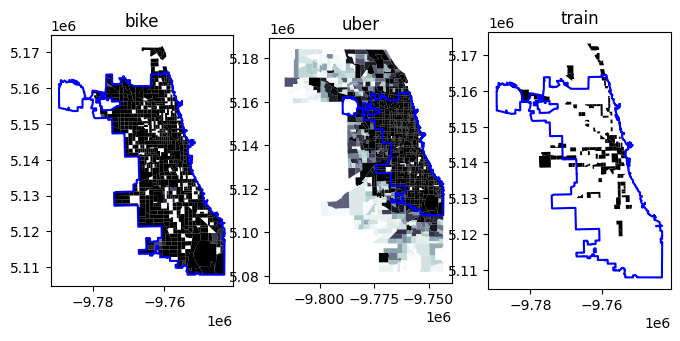

In [24]:
import matplotlib.pyplot as plt
from data.constants import CHI_BOUNDARY_FILE
plot_data = tract_missing.groupby(['id','transit'])['missing'].mean().reset_index()
plot_data = plot_data.merge(tracts[['geoid10','geometry']],left_on='id',right_on='geoid10')
plot_data = gpd.GeoDataFrame(plot_data, geometry='geometry').to_crs(WEB_CRS)
chi_bound = gpd.read_file(CHI_BOUNDARY_FILE).to_crs(WEB_CRS)
fig, axs = plt.subplots(1, plot_data.transit.nunique(), figsize=(8,8))
for t, ax in zip(plot_data.transit.unique(), axs):
    fig = plot_data[plot_data.transit==t].plot('missing', cmap='bone',ax=ax)
    chi_bound.boundary.plot(ax=fig, color='blue')
    fig.set_title(t)

# This is consistent with my expectation of where we expect to have data

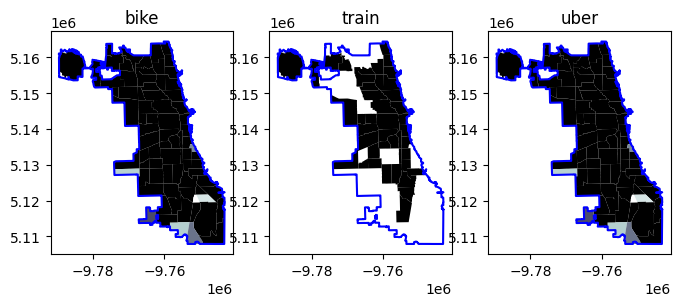

In [25]:
import matplotlib.pyplot as plt
from data.constants import CHI_BOUNDARY_FILE
plot_data = comm_missing.groupby(['id','transit'])['missing'].mean().reset_index()
plot_data = plot_data.merge(comms[['comm_area','geometry']],left_on='id',right_on='comm_area')
plot_data = gpd.GeoDataFrame(plot_data, geometry='geometry').to_crs(WEB_CRS)
chi_bound = gpd.read_file(CHI_BOUNDARY_FILE).to_crs(WEB_CRS)
fig, axs = plt.subplots(1, plot_data.transit.nunique(), figsize=(8,8))
for t, ax in zip(plot_data.transit.unique(), axs):
    fig = plot_data[plot_data.transit==t].plot('missing', cmap='bone',ax=ax)
    chi_bound.boundary.plot(ax=fig, color='blue')
    fig.set_title(t)

# This is consistent with my expectation of where we expect to have data

# Interpretation of unbalanced panel

According to Woldridge (p. 491), attrition is ok if it is random and uncorrelated with 
the unobserved error. Also, it's ok for data to be missing due to exogeneous
variables, e.g. E(wage|age > 35). It's not ok for it to be missing due to 
endogenous variable E(wage > 50k|age). 

The sparsity of train census tracts makes me wonder if we should use a voronoi
tesselation or some other larger aerial unit of the population the train is serving.
I'm actually surprised the bus tract coverage is so complete in this regard.